# Practical 5: Box-Jenkins ARIMA Modeling
## Dataset: catfish.xls
## Objective: Perform stationarity testing, determine ARIMA orders (p,d,q) from ACF/PACF plots, fit and forecast using ARIMA model

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [4]:
df = pd.read_csv("catfish.xls")

In [5]:
df.head(5)

,Date,Total
0,1986-1-01,9034
1,1986-2-01,9596
2,1986-3-01,10558
3,1986-4-01,9002
4,1986-5-01,9239


In [6]:
df.shape

(324, 2)

In [7]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.set_index("Date")

In [8]:
df.head(5)

,Total
Date,
1986-01-01,9034
1986-02-01,9596
1986-03-01,10558
1986-04-01,9002
1986-05-01,9239


Text(0, 0.5, 'Catfish Sales')

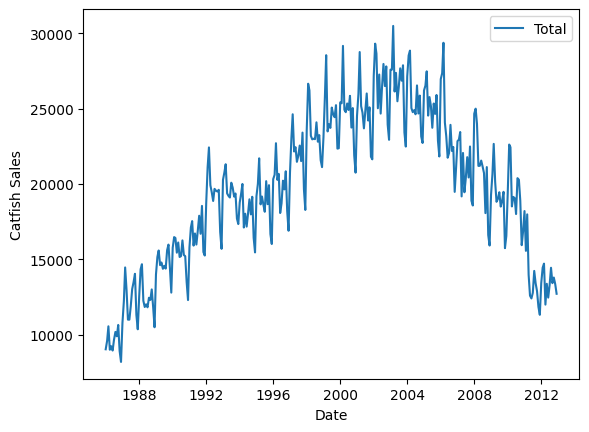

In [9]:
sns.lineplot(df)
plt.ylabel("Catfish Sales")

### 📊 How to Read This Graph:
- Monthly catfish sales showing trend and some volatility.
- We need to check if this data is stationary before applying ARIMA.

In [10]:
#ADF and KPSS Test on Raw Data
print("ADF Statistic:", adfuller(df["Total"])[0])
print("ADF p-value:", adfuller(df["Total"])[1])
print("KPSS p-value:", kpss(df["Total"])[1])

ADF Statistic: -1.5899031233340126
ADF p-value: 0.4886635157188413
KPSS p-value: 0.01


C:\Users\tejas\AppData\Local\Temp\ipykernel_5988\3369551009.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("ADF Statistic:", adfuller(df["Total"])[0])
C:\Users\tejas\AppData\Local\Temp\ipykernel_5988\3369551009.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("ADF p-value:", adfuller(df["Total"])[1])
C:\Users\tejas\AppData\Local\Temp\ipykernel_5988\336

In [11]:
#First Differencing for Stationarity (d=1)
diff_catfish = df["Total"].diff().dropna()

print("Differenced ADF p-value:", adfuller(diff_catfish)[1])
print("Differenced KPSS p-value:", kpss(diff_catfish)[1])

Differenced ADF p-value: 0.00042523708517151434
Differenced KPSS p-value: 0.04448905017699089


C:\Users\tejas\AppData\Local\Temp\ipykernel_5988\3352335423.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("Differenced ADF p-value:", adfuller(diff_catfish)[1])
C:\Users\tejas\AppData\Local\Temp\ipykernel_5988\3352335423.py:5: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("Differenced KPSS p-value:", kpss(diff_catfi

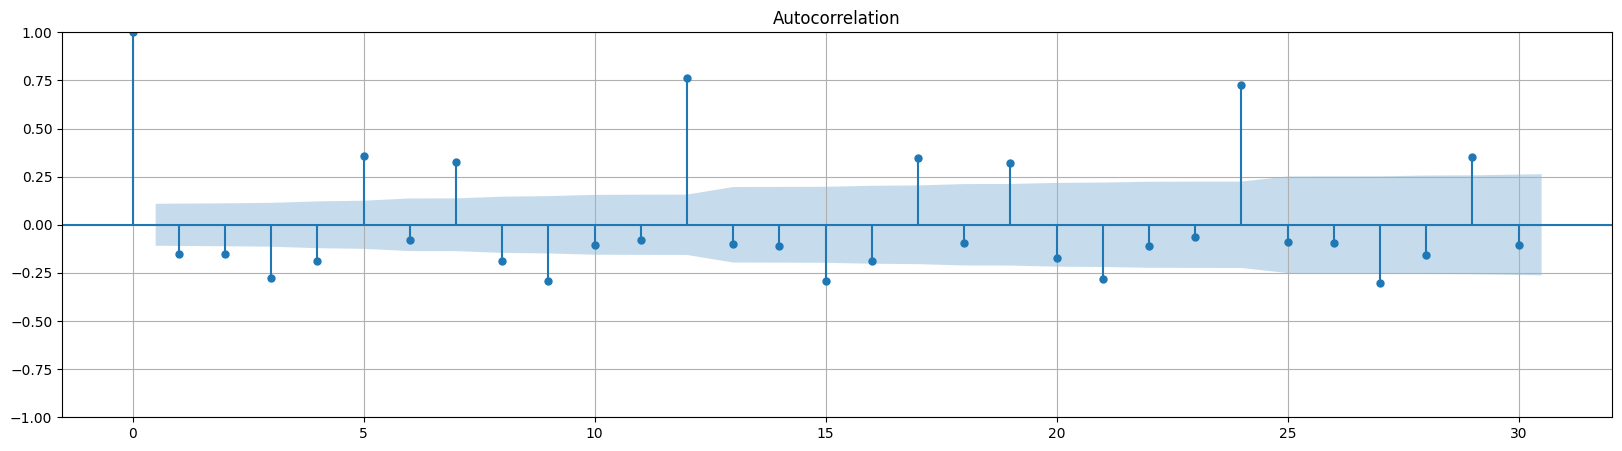

In [12]:
#ACF Plot - used to determine MA order (q)
plt.figure(figsize = (20,5))
plt.grid()
plot_acf(diff_catfish, ax = plt.gca(), lags = 30)
plt.show()

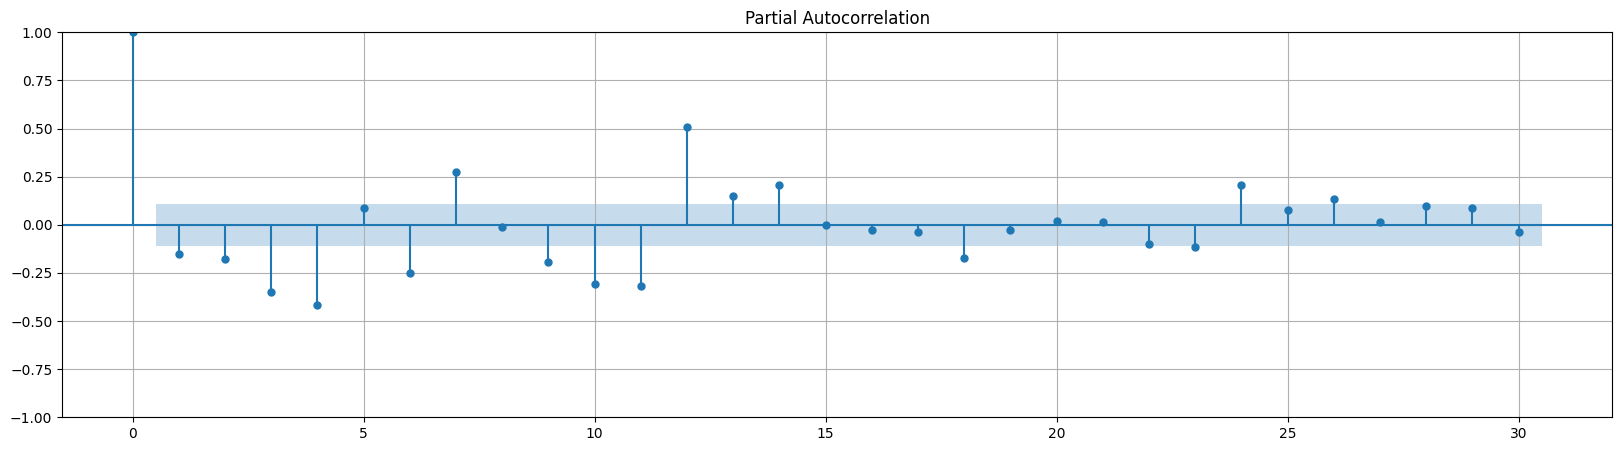

In [13]:
#PACF Plot - used to determine AR order (p)
plt.figure(figsize = (20,5))
plt.grid()
plot_pacf(diff_catfish, ax = plt.gca(), lags = 30)
plt.show()

### 📊 How to Read ACF & PACF for ARIMA Order Selection:
- **PACF**: Look at where bars first cut into the blue shaded region. That lag = AR order **p**.
- **ACF**: Look at where bars first cut into the blue shaded region. That lag = MA order **q**.
- **d** = number of times we differenced the data (here d=1).

In [14]:
#Train Test Split (80% Train, 20% Test)
train_df = df[:int(df.shape[0]*0.8)]
test_df = df[int(df.shape[0]*0.8):]

In [15]:
#Fit ARIMA(1, 1, 1) Model
from statsmodels.tsa.arima.model import ARIMA

model_arima = ARIMA(train_df["Total"], order=(1, 1, 1))
model_arima_fit = model_arima.fit()
print(model_arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Total   No. Observations:                  259
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -2294.241
Date:                Sat, 26 Sep 2026   AIC                           4594.483
Time:                        08:46:28   BIC                           4605.142
Sample:                    01-01-1986   HQIC                          4598.769
                         - 07-01-2007                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4228      0.085      4.979      0.000       0.256       0.589
ma.L1         -0.8476      0.066    -12.873      0.000      -0.977      -0.719
sigma2      3.176e+06   3.17e+05     10.010      0.0

c:\Users\tejas\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tejas\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tejas\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tejas\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\tejas\AppData\Local

### 📝 How to Read ARIMA Summary Table:
- **coef**: The learned AR and MA coefficient values.
- **P>|z|**: The p-value for each coefficient. If p < 0.05, that coefficient is statistically significant.
- **AIC**: Akaike Information Criterion. Lower AIC = better model.

In [16]:
#Forecast and MAPE Evaluation
from sklearn.metrics import mean_absolute_percentage_error

forecast_arima = model_arima_fit.forecast(len(test_df))
mape = mean_absolute_percentage_error(test_df["Total"], forecast_arima)
print("ARIMA Forecast MAPE:", mape)

ARIMA Forecast MAPE: 0.2949033752093577


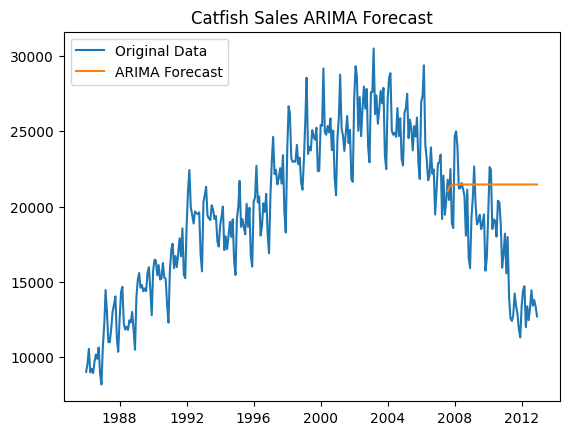

In [17]:
#Plot Actual vs Forecast
plt.plot(df["Total"], label="Original Data")
plt.plot(forecast_arima, label="ARIMA Forecast")
plt.legend()
plt.title("Catfish Sales ARIMA Forecast")
plt.show()

### 📊 How to Read the ARIMA Forecast Plot:
- **Blue line** = full original data (train + test).
- **Orange line** = ARIMA model forecast for the test period.
- Compare how closely the orange line follows the blue line in the test region.